In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import silhouette_score

In [ ]:
df=pd.read_csv("/content/sales_data_sample.csv", encoding='latin1')
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  ...  CONTACTFIRSTNAME  DEALSIZE
0        10107               30  ...              Kwai     Small
1        10121               34  ...              Paul     Small
2        10134               41  ...            Daniel    Medium
3        10145               45  ...             Julie    Medium
4        10159               49  ...             Julie    Medium

[5 rows x 25 columns]


In [ ]:
numeric_cols=df.select_dtypes(include=['int64','float64']).columns
X=df[numeric_cols]

In [ ]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)


In [ ]:
wcss=[]
for i in range(1,11):
  kmeans=KMeans(n_clusters=i, random_state=50)
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)

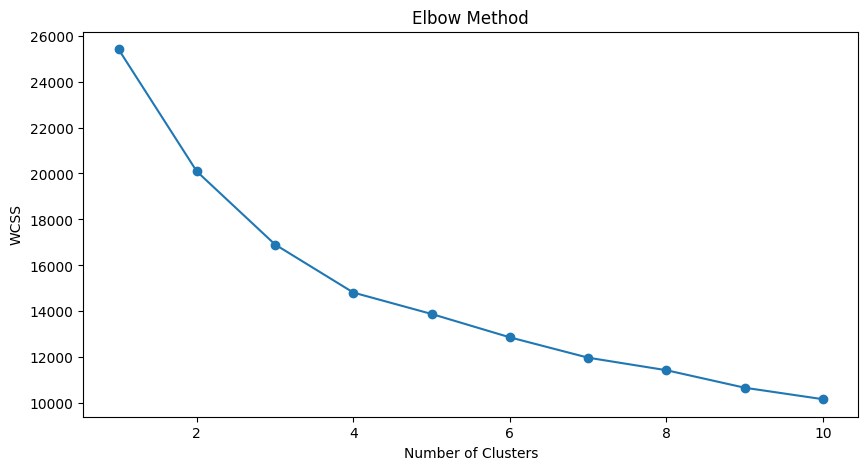

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(range(1,11),wcss,marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

In [ ]:
k=3
kmeans=KMeans(n_clusters=k, random_state=50)
df['KMeans_CLuster']= kmeans.fit_predict(X_scaled)
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  ...  DEALSIZE  KMeans_CLuster
0        10107               30  ...     Small               0
1        10121               34  ...     Small               2
2        10134               41  ...    Medium               0
3        10145               45  ...    Medium               0
4        10159               49  ...    Medium               0

[5 rows x 26 columns]


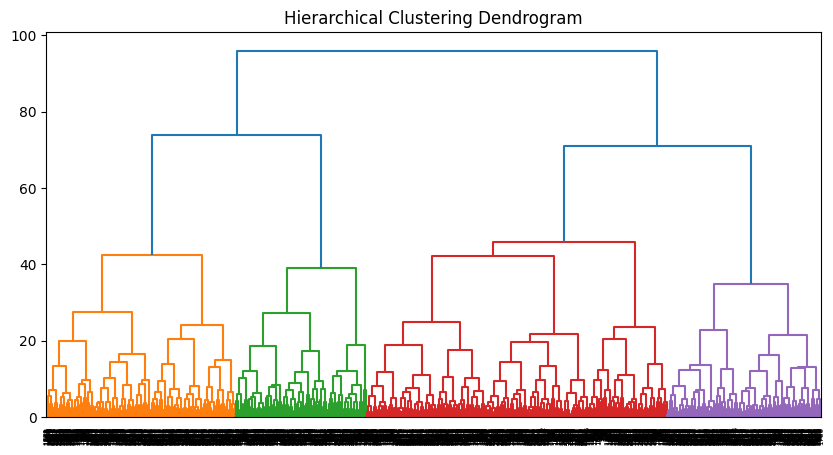

In [ ]:
linked=linkage(X_scaled, method='ward')

plt.figure(figsize=(10,5))
dendrogram(linked, orientation='top', distance_sort='descending' , show_leaf_counts=True)
plt.title('Hierarchical Clustering Dendrogram')
plt.show()

In [ ]:
df['Hier_Cluster']=fcluster(linked,k,criterion='maxclust')
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  ...  KMeans_CLuster  Hier_Cluster
0        10107               30  ...               0             3
1        10121               34  ...               2             3
2        10134               41  ...               0             1
3        10145               45  ...               0             1
4        10159               49  ...               0             1

[5 rows x 27 columns]


In [ ]:
score = silhouette_score(X_scaled, kmeans.labels_)
print("Silhouette Score:", score)

Silhouette Score: 0.19592401643087726
